# Second round

This notebook records the second round under `configs/second_round.yaml`. Each variant was chosen on the tuning window, 2007-2013, and each chosen variant then ran once. The ideas came from seeing the evaluation window, so **every evaluation-window number here is a second look**: weaker evidence than the pre-registered headline, and it can't replace it.

Results are read from `reports/second_round/`, and the summary is in `reports/second_round/SUMMARY.md`.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

OUT = Path("../reports/second_round")
FIG = OUT / "figures"
FIG.mkdir(exist_ok=True)
DATA = Path("../data/processed/second_round")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.max_colwidth", 60)
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
meta = json.loads((OUT / "run_metadata.json").read_text())
display(pd.read_csv(OUT / "checks.csv")[["check", "variant", "value", "limit", "passed"]])
evaluation = pd.read_csv(OUT / "evaluation.csv")
grid = pd.read_csv(OUT / "tuning" / "variant_grid.csv")
{k: meta[k] for k in ("code_commit", "code_dirty", "n_variants_tried", "evidence", "holdout_start")}

,check,variant,value,limit,passed
0,recorded_book,no_trade_band__lightgbm_h5_rank__neutral_volscaled__0,6.938894e-18,1.000000e-09,True
1,recorded_book,liquid_universe__lightgbm_h5_rank__neutral_volscaled__1,6.938894e-18,1.000000e-09,True
2,recorded_book,no_trade_band__B0_reversal_h5__neutral_volscaled__0,6.938894e-18,1.000000e-09,True
3,recorded_book,liquid_universe__B0_reversal_h5__optimised__1,0.000000e+00,1.000000e-06,True
4,recorded_book,liquid_universe__B0_reversal_h5__neutral_volscaled__1,6.938894e-18,1.000000e-09,True
5,recorded_book,liquid_universe__lightgbm_h5_rank__optimised__1,0.000000e+00,1.000000e-06,True
6,every_variant_tuned,all,0.000000e+00,0.000000e+00,True
7,tuning_isolation,all,0.000000e+00,0.000000e+00,True


{'code_commit': 'a621f2d212ceb33d180ecaacdb2cb306a6833c54',
 'code_dirty': False,
 'n_variants_tried': 62,
 'evidence': 'second_look',
 'holdout_start': '2022-01-01'}

## Tuning-window choices

These were fixed and committed before any evaluation-window return of a variant existed. The net Sharpes below are in-sample for the choices. The liquid curve for `optimised` LightGBM isn't smooth: 0.35, 0.26, then 0.62.

,variant,recorded,net_sharpe,on_grid_edge
0,liquid_universe__B0_reversal_h5__neutral_volscaled__0.25,False,-1.151,True
1,liquid_universe__B0_reversal_h5__optimised__1,True,0.447,True
2,liquid_universe__lightgbm_h5_rank__neutral_volscaled__0.25,False,-0.466,True
3,liquid_universe__lightgbm_h5_rank__optimised__0.25,False,0.624,True
4,no_trade_band__B0_reversal_h5__neutral_volscaled__4,False,-0.061,True
5,no_trade_band__lightgbm_h5_rank__neutral_volscaled__4,False,0.316,True
6,wider_lambda_grid__B0_reversal_h5__optimised__1_1,False,0.472,True
7,wider_lambda_grid__lightgbm_h5_rank__optimised__100_4,True,0.345,False


,variant,net_sharpe,net_nw_t,mean_gross_exposure,net_vol_ann
0,liquid_universe__lightgbm_h5_rank__optimised__0.25,0.624,1.677,0.225,0.011


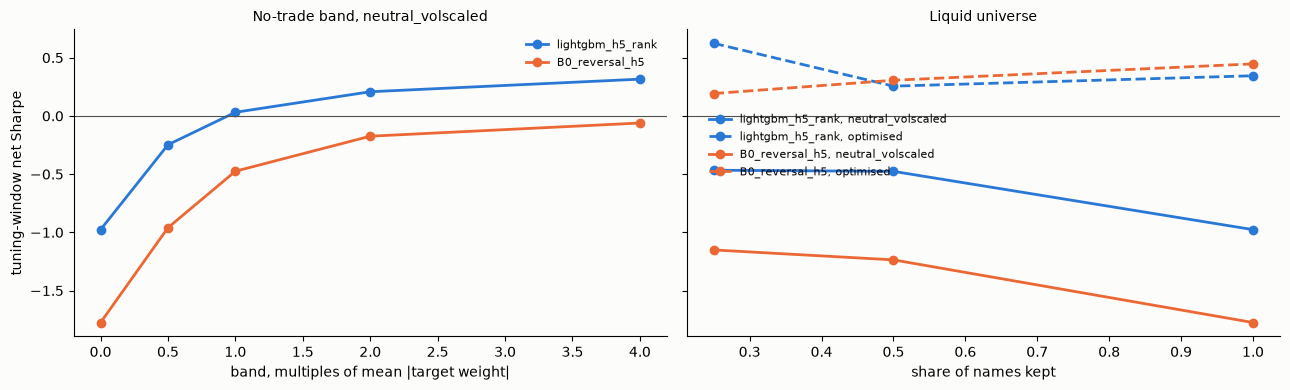

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for signal, color in (("lightgbm_h5_rank", BLUE), ("B0_reversal_h5", ORANGE)):
    g = grid[(grid["family"] == "no_trade_band") & (grid["signal"] == signal)].sort_values("band")
    axes[0].plot(g["band"], g["net_sharpe"], marker="o", lw=2, ms=6, color=color, label=signal)
    for construction, style in (("neutral_volscaled", "-"), ("optimised", "--")):
        g = grid[(grid["family"] == "liquid_universe") & (grid["signal"] == signal) & (grid["construction"] == construction)].sort_values("fraction")
        axes[1].plot(g["fraction"], g["net_sharpe"], marker="o", lw=2, ms=6, ls=style, color=color, label=f"{signal}, {construction}")
axes[0].set_title("No-trade band, neutral_volscaled", fontsize=10)
axes[1].set_title("Liquid universe", fontsize=10)
axes[0].set_xlabel("band, multiples of mean |target weight|")
axes[1].set_xlabel("share of names kept")
axes[0].set_ylabel("tuning-window net Sharpe")
for ax in axes:
    ax.axhline(0, color="#52514e", lw=0.8)
axes[0].legend(frameon=False, fontsize=8)
axes[1].legend(frameon=False, fontsize=8, loc="center left", bbox_to_anchor=(0.02, 0.62))
fig.tight_layout()
fig.savefig(FIG / "tuning_choices.png", dpi=150)
display(pd.read_csv(OUT / "tuning" / "selected_variants.csv")[["variant", "recorded", "net_sharpe", "on_grid_edge"]].round(3))
display(pd.read_csv(OUT / "tuning" / "holdout_candidate.csv")[["variant", "net_sharpe", "net_nw_t", "mean_gross_exposure", "net_vol_ann"]].round(3))

## Second look: the evaluation window

The holdout candidate reaches 0.38 net (t 1.09), but its interval contains zero, and so does its gap from the recorded book. It's a very small book: about 0.25 of gross and 0.8% vol.

LightGBM band 4 is the only variant whose interval sits above zero, at 0.71 net (t 2.04). It rose out of sample, from 0.32 to 0.71. It isn't the holdout candidate, because its tuning figure was below the headline's, and that can't be changed now without choosing on the evaluation window.

,evidence,variant,tuning_net_sharpe,net_sharpe,net_nw_t,net_sharpe_ci_low,net_sharpe_ci_high,difference,difference_ci_low,difference_ci_high,net_return_ann,net_vol_ann,gross_sharpe,annual_turnover
0,second_look,liquid_universe__B0_reversal_h5__neutral_volscaled__0.25,-1.15,-1.01,-2.60,-1.73,-0.33,0.12,-0.26,0.55,-0.08,0.08,0.48,71.62
1,second_look,no_trade_band__B0_reversal_h5__neutral_volscaled__4,-0.06,-1.17,-3.33,-1.89,-0.50,-0.03,-0.99,0.94,-0.02,0.01,-1.02,0.73
2,second_look,liquid_universe__B0_reversal_h5__optimised__1,0.45,-0.03,-0.07,-0.79,0.65,0.00,0.00,0.00,-0.00,0.07,0.26,9.93
3,second_look,wider_lambda_grid__B0_reversal_h5__optimised__1_1,0.47,-0.06,-0.15,-0.84,0.62,-0.03,-0.15,0.08,-0.01,0.09,0.20,10.87
4,second_look,liquid_universe__lightgbm_h5_rank__neutral_volscaled__0.25,-0.47,-0.57,-1.72,-1.20,0.06,-0.30,-0.70,0.07,-0.05,0.08,0.49,55.29
5,second_look,no_trade_band__lightgbm_h5_rank__neutral_volscaled__4,0.32,0.71,2.04,0.09,1.35,0.97,0.29,1.69,0.02,0.02,0.86,1.50
6,second_look,liquid_universe__lightgbm_h5_rank__optimised__0.25,0.62,0.38,1.09,-0.29,1.07,0.39,-0.35,1.13,0.00,0.01,0.48,0.45
7,second_look,wider_lambda_grid__lightgbm_h5_rank__optimised__100_4,0.35,-0.00,-0.00,-0.60,0.62,0.00,0.00,0.00,-0.00,0.02,0.14,1.18


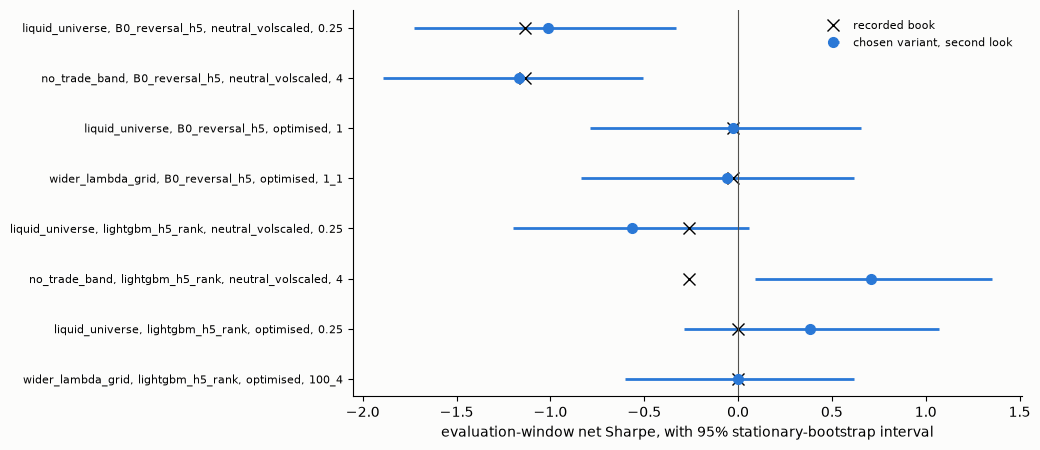

In [3]:
e = evaluation.sort_values(["signal", "construction", "family"]).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10.5, 4.6))
y = np.arange(len(e))
ax.errorbar(e["net_sharpe"], y, xerr=[e["net_sharpe"] - e["net_sharpe_ci_low"], e["net_sharpe_ci_high"] - e["net_sharpe"]],
            fmt="o", ms=7, lw=2, color=BLUE, label="chosen variant, second look")
ax.plot(e["recorded_net_sharpe"], y, "kx", ms=9, label="recorded book")
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_yticks(y, [v.replace("__", ", ") for v in e["variant"]], fontsize=8)
ax.invert_yaxis()
ax.set_xlabel("evaluation-window net Sharpe, with 95% stationary-bootstrap interval")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "second_look_intervals.png", dpi=150)
display(e[["evidence", "variant", "tuning_net_sharpe", "net_sharpe", "net_nw_t", "net_sharpe_ci_low", "net_sharpe_ci_high",
           "difference", "difference_ci_low", "difference_ci_high", "net_return_ann", "net_vol_ann", "gross_sharpe", "annual_turnover"]].round(2))

## What the two books held

These come from columns the run already recorded. No new statistic is estimated here. Both books stay neutral. Band 4 starts flat and takes years to build its gross exposure, because the band keeps most names out at first, so its holdings depend on the start date. Most of its evaluation-window return arrives in 2016-2019. It's positive in all 8 evaluation years but trades about 1.5× a year, so it no longer acts like a five-day book.

,LightGBM band 4,"candidate, LightGBM top 25%"
mean gross,1.3251,0.2545
max |net exposure|,0.0099,0.0046
mean |ex-ante beta|,0.0021,0.0051


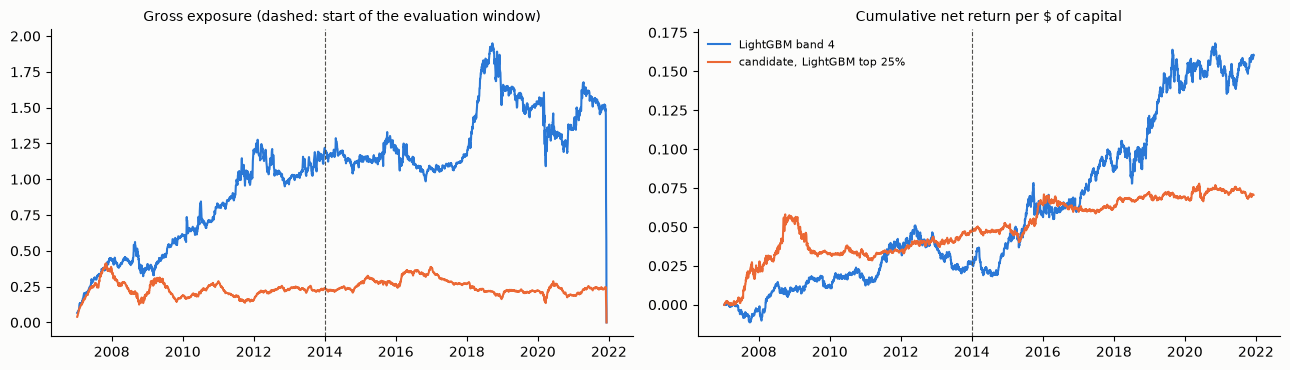

In [4]:
books = {"LightGBM band 4": "no_trade_band__lightgbm_h5_rank__neutral_volscaled__4",
         "candidate, LightGBM top 25%": "liquid_universe__lightgbm_h5_rank__optimised__0.25"}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
rows = {}
for (name, variant), color in zip(books.items(), (BLUE, ORANGE)):
    d = pd.read_parquet(DATA / f"{variant}.parquet")
    d["date"] = pd.to_datetime(d["date"])
    d = d.set_index("date").sort_index().loc["2007-01-11":]
    axes[0].plot(d["gross_exposure"], color=color, lw=1.5, label=name)
    axes[1].plot(d["net_pnl"].cumsum(), color=color, lw=1.5, label=name)
    x = d.loc["2014-01-02":]
    rows[name] = {"mean gross": x["gross_exposure"].mean(), "max |net exposure|": x["net_exposure"].abs().max(),
                  "mean |ex-ante beta|": x["beta_ex_ante"].abs().mean()}
for ax in axes:
    ax.axvline(pd.Timestamp("2014-01-01"), color="#52514e", lw=0.8, ls="--")
axes[0].set_title("Gross exposure (dashed: start of the evaluation window)", fontsize=10)
axes[1].set_title("Cumulative net return per $ of capital", fontsize=10)
axes[1].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG / "band_and_candidate.png", dpi=150)
display(pd.DataFrame(rows).round(4))

## Conclusion

The headline doesn't change. The candidate goes forward by the rule, but its second look is unremarkable. Band 4 is the most interesting result of the round, and it's the least understood. It needs its own pre-registered attribution before anyone treats it as more than a second look.